# FXS / 03c — Cost sensitivity of the 03b portfolio: spread 0–3× Dukascopy, commission $0–8 per lot

Same portfolio and period as 03b: EURUSD-02 + USDJPY-01 + USDJPY-02, every trading day, 2021-01 → 2026-11-06, $6,000 start, size = L × current equity per structure (compounding).

For **each leverage** (1, 2, 3, 5, 10× per structure) a table of the **annual return (CAGR, %)** over:
- **rows:** spread as a multiple of the Dukascopy quoted spread (0 = filled at the mid, 1 = Dukascopy, 3 = three times wider);
- **columns:** commission in USD per 100,000-unit lot, round trip ($0 → $8).

A second set of tables gives the maximum drawdown. Reference points: Dukascopy spread ≈ 0.3 pips (EURUSD) and ≈ 0.3–0.6 pips (USDJPY); raw/ECN brokers $6–7 per lot round trip; FundedNext about $3.

Descriptive, like 03b: the structures were chosen with 2021–2025 results, and 2026 has already been seen.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 6_000.0
LEVERAGES = [1, 2, 3, 5, 10]
SPREAD_FACTORS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0]
COMMISSIONS = [0, 1, 2, 3, 4, 5, 6, 7, 8]          # USD per lot, round trip
IDS = ["EURUSD-02", "USDJPY-01", "USDJPY-02"]
FROZEN = {"EURUSD-02": ("NY", 660, 900, -1), "USDJPY-01": ("UTC", 55, 115, -1), "USDJPY-02": ("UTC", 25, 55, 1)}
WINDOWS = ((dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"), (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs03c_")
    os.environ.pop("DUKASCOPY_DIR", None)
    LEVERAGES, SPREAD_FACTORS, COMMISSIONS = [1, 5], [0.0, 1.0, 3.0], [0, 3, 8]
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("03c_synthetic" if SYNTHETIC else "03c"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(("EURUSD", "USDJPY")):
        F.write_synthetic_candles(base, p, dt.date(2020, 12, 28), dt.date(2026, 11, 6), seed=7 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": k, "pair": k[:6], "clock": c, "start": s, "end": e, "direction": d} for k, (c, s, e, d) in FROZEN.items()])
else:
    cand = F.load_frozen_candidates(BRANCH).query("id in @IDS").reset_index(drop=True)
for _, r in cand.iterrows():
    assert (r["clock"], int(r["start"]), int(r["end"]), int(r["direction"])) == FROZEN[r["id"]], f"{r['id']} is not the frozen rule"
PAIR_OF = cand.set_index("id")["pair"]

## 1. Returns at the mid and the cost of one Dukascopy spread, per trade

Any spread multiple `s` is then `mid return − s × Dukascopy spread`, and any commission `c` is `c / (100,000 × base-currency value)`.

In [3]:
def detail(sf):
    parts = [F.structure_detail(cand, a, b, st, cfg, with_price=True, spread_factor=sf) for a, b, st in WINDOWS]
    return [pd.concat([x[k] for x in parts]).sort_index()[IDS] for k in range(3)]
for p in sorted(set(PAIR_OF)):
    for a, b, _ in WINDOWS:
        cov = F.file_coverage(p, a, b)
        assert cov["share"] >= cfg.min_file_share, f"{p} {a.year}: only {cov['share']:.1%} of day files"
G_mid, M_mid, P = detail(0.0)
G_one, M_one, _ = detail(1.0)
G_mid, G_one, M_mid, M_one = (x.fillna(0.0) for x in (G_mid, G_one, M_mid, M_one))
P = P.ffill().bfill()
SPREAD = G_mid - G_one                                          # one Dukascopy spread per trade (>= 0), bps
traded = G_one != 0
pip = lambda X, i: F.bps_to_pips(X[i], P[i], PAIR_OF[i])
ref = pd.DataFrame({"trades": traded.sum(),
                    "mid-to-mid pips/trade": pd.Series({i: pip(G_mid, i)[traded[i]].mean() for i in IDS}),
                    "Dukascopy spread, pips/trade": pd.Series({i: pip(SPREAD, i)[traded[i]].mean() for i in IDS}),
                    "$1/lot commission, pips": pd.Series({i: F.bps_to_pips(F.commission_bps_per_lot(PAIR_OF[i], 1.0), P[i][traded[i]], PAIR_OF[i]).mean() for i in IDS})})
display(ref.round(3)); ref.to_csv(OUT / "03c_reference.csv")

,trades,mid-to-mid pips/trade,"Dukascopy spread, pips/trade","$1/lot commission, pips"
EURUSD-02,1514,2.057,0.345,0.101
USDJPY-01,1516,1.688,0.586,0.140
USDJPY-02,1514,1.611,0.596,0.140


## 2. The grid

For each leverage, spread multiple and commission: the compounding account from $6,000, 2021-01 → 2026-11.

In [4]:
comm1 = pd.Series({i: F.commission_bps_per_lot(PAIR_OF[i], 1.0) for i in IDS})
rows = []
for L in LEVERAGES:
    w = pd.Series(float(L), index=IDS)
    for sf in SPREAD_FACTORS:
        for c in COMMISSIONS:
            N = G_mid - sf * SPREAD - c * comm1
            st = F.account_stats(F.simulate_account(N, w, E0), E0)
            rows.append({"L": L, "spread_x": sf, "commission": c, "cagr": st["cagr"], "final_equity": st["final_equity"],
                         "max_drawdown": st["max_drawdown"], "worst_year": st["worst_year"], "ruined": st["ruined"]})
grid = pd.DataFrame(rows)
grid.to_csv(OUT / "03c_grid.csv", index=False)
print(len(grid), "accounts simulated")

405 accounts simulated


## 3. Annual return (CAGR, %) per leverage

Rows: spread × Dukascopy. Columns: commission $ per lot round trip. The black box marks Dukascopy spread at $3 per lot.


=== 1x per structure: annual return, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,10.8,10.0,9.2,8.5,7.7,6.9,6.1,5.3,4.7
0.250000,10.0,9.2,8.4,7.7,6.9,6.1,5.4,4.7,4.0
0.500000,9.3,8.5,7.6,6.9,6.2,5.3,4.7,4.0,3.3
0.750000,8.5,7.6,7.0,6.2,5.4,4.7,4.0,3.3,2.4
1.000000,7.6,6.9,6.2,5.4,4.7,4.0,3.3,2.4,1.6
1.500000,6.2,5.4,4.7,4.0,3.3,2.4,1.6,1.0,0.4
2.000000,4.7,4.0,3.3,2.5,1.7,1.0,0.4,-0.3,-1.0
2.500000,3.3,2.5,1.7,1.1,0.4,-0.3,-1.0,-1.7,-2.4
3.000000,1.7,1.1,0.5,-0.3,-1.0,-1.7,-2.4,-3.1,-3.7



=== 2x per structure: annual return, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,23.6,21.7,20.0,18.1,16.4,14.8,13.1,11.3,9.7
0.250000,21.7,20.0,18.2,16.4,14.7,13.1,11.4,9.7,8.1
0.500000,20.0,18.2,16.4,14.7,13.1,11.5,9.6,8.1,6.6
0.750000,18.3,16.4,14.7,13.2,11.4,9.7,8.1,6.6,5.0
1.000000,16.5,14.7,13.2,11.4,9.7,8.1,6.6,5.1,3.5
1.500000,13.1,11.5,9.8,8.1,6.6,5.2,3.6,2.0,0.7
2.000000,9.8,8.2,6.6,5.2,3.6,2.1,0.6,-0.8,-2.3
2.500000,6.6,5.0,3.6,1.9,0.5,-0.8,-2.4,-3.6,-5.3
3.000000,3.7,1.9,0.6,-0.8,-2.3,-3.6,-5.1,-6.4,-7.6



=== 3x per structure: annual return, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,37.5,34.4,31.4,28.6,25.7,22.8,20.1,17.4,14.9
0.250000,34.4,31.5,28.6,25.7,22.9,20.1,17.4,15.0,12.4
0.500000,31.5,28.6,25.7,22.9,20.2,17.5,14.9,12.3,9.9
0.750000,28.6,25.8,22.9,20.2,17.5,14.9,12.4,9.9,7.4
1.000000,25.7,23.0,20.2,17.6,14.9,12.3,9.9,7.5,5.1
1.500000,20.2,17.6,15.0,12.3,9.9,7.6,5.1,2.9,0.6
2.000000,15.1,12.5,10.0,7.5,5.3,2.9,0.6,-1.6,-3.8
2.500000,9.9,7.6,5.3,2.9,0.7,-1.6,-3.7,-5.7,-7.7
3.000000,5.3,3.0,0.6,-1.5,-3.7,-5.7,-7.8,-9.7,-11.6



=== 5x per structure: annual return, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,69.4,63.1,57.1,51.2,45.7,40.3,35.1,30.1,25.2
0.250000,63.1,57.1,51.3,45.7,40.3,35.1,30.0,25.3,20.6
0.500000,57.1,51.4,45.7,40.3,35.2,30.1,25.3,20.7,16.3
0.750000,51.3,45.8,40.4,35.2,30.2,25.3,20.7,16.2,12.0
1.000000,45.8,40.3,35.1,30.1,25.3,20.7,16.3,11.9,7.8
1.500000,35.3,30.3,25.5,20.8,16.3,12.1,8.0,3.9,0.0
2.000000,25.5,20.8,16.4,12.1,8.0,4.0,0.2,-3.5,-7.0
2.500000,16.4,12.2,8.0,4.0,0.3,-3.4,-6.9,-10.3,-13.6
3.000000,8.1,4.1,0.3,-3.4,-6.8,-10.3,-13.3,-16.5,-19.7



=== 10x per structure: annual return, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,176.1,155.9,137.4,120.1,104.1,89.2,75.4,62.7,50.9
0.250000,156.1,137.5,120.2,104.1,89.3,75.5,62.8,50.9,39.9
0.500000,137.7,120.3,104.3,89.4,75.6,62.9,51.0,40.0,29.8
0.750000,120.4,104.4,89.5,75.8,63.0,51.1,40.1,29.9,20.5
1.000000,104.4,89.6,75.8,63.0,51.1,40.2,30.0,20.6,11.8
1.500000,76.0,63.2,51.3,40.3,30.1,20.7,11.9,3.6,-3.7
2.000000,51.4,40.4,30.2,20.7,12.0,3.8,-3.8,-10.5,-17.1
2.500000,30.3,20.8,12.1,3.9,-3.6,-10.6,-16.9,-22.9,-28.0
3.000000,12.1,4.0,-3.5,-10.4,-16.9,-22.8,-28.1,-32.8,-37.2


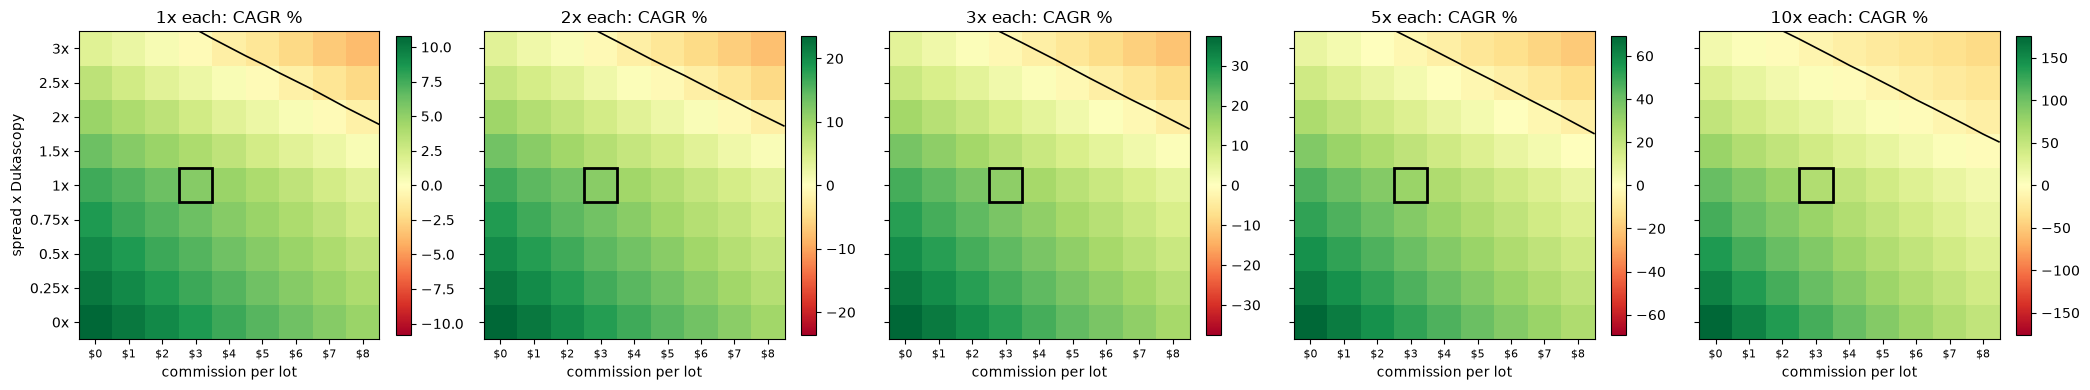

In [5]:
def table(L, col):
    return grid[grid["L"] == L].pivot(index="spread_x", columns="commission", values=col)

for L in LEVERAGES:
    t = 100 * table(L, "cagr")
    print(f"\n=== {L}x per structure: annual return, % ===")
    display(t.round(1).style.background_gradient(cmap="RdYlGn", vmin=-30, vmax=30, axis=None).format("{:.1f}"))
    t.to_csv(OUT / f"03c_cagr_L{L}.csv")

fig, axes = plt.subplots(1, len(LEVERAGES), figsize=(4.2 * len(LEVERAGES), 4), sharey=True)
for ax, L in zip(np.atleast_1d(axes), LEVERAGES):
    t = 100 * table(L, "cagr")
    lim = max(5.0, float(np.nanmax(np.abs(t.to_numpy()))))
    im = ax.imshow(t.to_numpy(), cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto", origin="lower")
    ax.contour(t.to_numpy(), levels=[0], colors="black", linewidths=1.2, origin="lower")
    ax.set_xticks(range(len(t.columns))); ax.set_xticklabels([f"${c}" for c in t.columns], fontsize=8)
    ax.set_yticks(range(len(t.index))); ax.set_yticklabels([f"{s:g}x" for s in t.index])
    if 1.0 in list(t.index) and 3 in list(t.columns):
        y, x = list(t.index).index(1.0), list(t.columns).index(3)
        ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, ec="black", lw=2))
    ax.set_title(f"{L}x each: CAGR %"); ax.set_xlabel("commission per lot")
    fig.colorbar(im, ax=ax, fraction=0.045)
np.atleast_1d(axes)[0].set_ylabel("spread x Dukascopy")
plt.tight_layout(); plt.savefig(OUT / "03c_cagr_heatmaps.png", dpi=110); plt.show()

## 4. Maximum drawdown (%) per leverage

In [6]:
for L in LEVERAGES:
    t = 100 * table(L, "max_drawdown")
    print(f"\n=== {L}x per structure: maximum drawdown, % ===")
    display(t.round(1).style.background_gradient(cmap="RdYlGn", vmin=-60, vmax=0, axis=None).format("{:.1f}"))
    t.to_csv(OUT / f"03c_maxdd_L{L}.csv")


=== 1x per structure: maximum drawdown, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,-3.5,-3.4,-3.6,-3.8,-3.7,-4.0,-4.3,-4.8,-5.3
0.250000,-3.4,-3.6,-3.9,-3.8,-4.0,-4.3,-4.7,-5.2,-6.2
0.500000,-3.7,-4.0,-3.8,-4.0,-4.3,-4.6,-5.1,-6.1,-7.3
0.750000,-4.0,-3.9,-4.1,-4.4,-4.6,-5.0,-6.0,-7.2,-8.5
1.000000,-3.9,-4.2,-4.4,-4.7,-4.8,-5.9,-7.1,-8.4,-10.2
1.500000,-4.6,-4.7,-4.8,-5.6,-6.8,-8.1,-10.0,-11.6,-13.7
2.000000,-4.7,-5.4,-6.6,-7.7,-9.7,-11.4,-13.6,-15.6,-17.6
2.500000,-6.3,-7.4,-9.5,-11.3,-13.5,-15.5,-17.5,-19.8,-21.8
3.000000,-9.1,-11.1,-13.4,-15.4,-17.8,-19.7,-21.7,-23.6,-25.3



=== 2x per structure: maximum drawdown, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,-7.0,-7.2,-7.4,-7.6,-7.9,-8.2,-8.7,-9.5,-11.2
0.250000,-7.3,-7.5,-7.7,-8.0,-8.3,-8.7,-9.5,-11.1,-13.1
0.500000,-7.5,-7.8,-8.1,-8.4,-8.8,-9.4,-10.9,-13.1,-14.6
0.750000,-8.0,-8.2,-8.5,-8.9,-9.4,-10.7,-12.7,-14.4,-16.4
1.000000,-8.3,-8.6,-9.1,-9.3,-10.5,-12.4,-14.3,-16.1,-19.6
1.500000,-9.2,-9.5,-10.1,-11.9,-13.5,-15.4,-19.2,-23.2,-27.0
2.000000,-10.0,-11.4,-13.1,-14.9,-19.0,-23.0,-26.7,-30.5,-34.1
2.500000,-12.8,-15.0,-18.9,-23.0,-26.9,-30.3,-34.2,-37.3,-41.1
3.000000,-18.6,-22.6,-26.9,-30.2,-33.9,-36.9,-40.5,-43.1,-46.1



=== 3x per structure: maximum drawdown, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,-10.5,-10.7,-11.0,-11.3,-11.8,-12.3,-13.1,-14.1,-17.0
0.250000,-10.8,-11.0,-11.5,-12.0,-12.4,-12.9,-14.0,-16.6,-19.4
0.500000,-11.2,-11.7,-12.1,-12.6,-13.0,-13.9,-16.3,-19.3,-21.9
0.750000,-11.8,-12.3,-12.8,-13.2,-13.9,-16.0,-18.8,-21.4,-24.1
1.000000,-12.4,-12.9,-13.3,-13.8,-15.5,-18.4,-21.1,-23.8,-28.9
1.500000,-13.7,-14.1,-14.8,-17.7,-20.4,-23.1,-28.5,-34.0,-38.5
2.000000,-14.9,-16.9,-19.8,-22.5,-28.0,-33.2,-38.5,-43.1,-47.8
2.500000,-19.1,-21.8,-27.7,-33.0,-37.8,-43.0,-47.6,-51.0,-54.8
3.000000,-27.0,-32.8,-38.2,-42.7,-47.4,-51.0,-54.7,-57.8,-61.2



=== 5x per structure: maximum drawdown, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,-17.1,-17.5,-17.9,-18.5,-19.3,-20.0,-21.2,-23.4,-27.7
0.250000,-17.6,-18.1,-18.8,-19.5,-20.2,-21.1,-22.8,-27.2,-31.1
0.500000,-18.3,-19.0,-19.8,-20.5,-21.2,-22.6,-26.6,-30.7,-34.6
0.750000,-19.3,-20.0,-20.7,-21.4,-22.5,-26.1,-30.1,-34.1,-37.9
1.000000,-20.2,-21.0,-21.6,-22.4,-25.4,-29.7,-33.5,-37.6,-45.2
1.500000,-22.1,-22.8,-24.3,-28.6,-32.5,-36.9,-44.5,-51.5,-57.6
2.000000,-23.9,-27.5,-31.6,-36.2,-44.1,-50.9,-56.9,-62.4,-67.2
2.500000,-30.7,-35.6,-43.8,-50.7,-56.8,-62.3,-67.0,-70.9,-74.7
3.000000,-43.0,-50.3,-56.7,-62.1,-66.7,-70.9,-74.3,-77.4,-80.3



=== 10x per structure: maximum drawdown, % ===


commission,0,1,2,3,4,5,6,7,8
spread_x,,,,,,,,,
0.000000,-32.1,-32.8,-33.6,-34.8,-35.9,-37.1,-39.2,-44.6,-50.6
0.250000,-33.0,-34.0,-35.2,-36.3,-37.5,-39.0,-43.7,-49.9,-55.4
0.500000,-34.4,-35.6,-36.7,-37.9,-39.0,-42.9,-49.1,-54.7,-59.7
0.750000,-35.9,-37.1,-38.2,-39.3,-42.0,-48.4,-54.1,-59.1,-66.4
1.000000,-37.5,-38.6,-39.7,-41.2,-47.6,-53.4,-58.5,-66.1,-74.0
1.500000,-40.4,-41.5,-46.0,-51.9,-57.2,-65.5,-73.6,-79.8,-84.4
2.000000,-44.4,-50.5,-55.9,-64.9,-73.1,-79.3,-84.3,-87.8,-90.8
2.500000,-54.6,-64.2,-72.6,-79.1,-84.1,-87.8,-90.6,-92.9,-94.3
3.000000,-72.1,-78.8,-83.8,-87.6,-90.6,-92.7,-94.3,-95.5,-96.3


## 5. Break-even: the highest commission that still leaves a positive return, at each spread multiple

In [7]:
be = {}
for L in LEVERAGES:
    t = table(L, "cagr")
    be[f"{L}x"] = pd.Series({sf: (max([c for c in t.columns if t.loc[sf, c] > 0]) if (t.loc[sf] > 0).any() else np.nan) for sf in t.index})
be = pd.DataFrame(be); be.index.name = "spread x Dukascopy"
display(be); be.to_csv(OUT / "03c_breakeven_commission.csv")
print("NaN = negative at every commission tested; the top of the range ($%d) means positive even at the highest commission." % max(COMMISSIONS))

,1x,2x,3x,5x,10x
spread x Dukascopy,,,,,
0.00,8,8,8,8,8
0.25,8,8,8,8,8
0.50,8,8,8,8,8
0.75,8,8,8,8,8
1.00,8,8,8,8,8
1.50,8,8,8,8,7
2.00,6,6,6,6,5
2.50,4,4,4,4,3
3.00,2,2,2,2,1


NaN = negative at every commission tested; the top of the range ($8) means positive even at the highest commission.


In [8]:
summary = {"study": "FXS03c", "descriptive": True, "synthetic": SYNTHETIC, "structures": IDS, "equity0": E0,
           "leverages": LEVERAGES, "spread_factors": SPREAD_FACTORS, "commissions_usd_per_lot_rt": COMMISSIONS,
           "reference": ref.round(4).reset_index().to_dict(orient="records"),
           "breakeven_commission": be.reset_index().to_dict(orient="records"),
           "note": "Same portfolio as 03b; hindsight selection; 2026 already seen in FXS 05/06."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\03c\summary.json
